# How to calculate z-scores in Python

“A z-score measures how many standard deviations an observation lies from the mean. We calculate it by subtracting the mean from the observation and dividing by the standard deviation. This standardizes the feature to mean zero and standard deviation one when the same data are used to estimate the population mean and standard deviation. If the original variable is normally distributed, its standardized version follows a standard normal distribution, which allows us to calculate probabilities using the normal CDF. In machine learning, standardization is especially useful for distance-based and scale-sensitive algorithms. We fit the scaler on training data only to prevent data leakage, and we don't assume that standardization makes a non-normal feature normally distributed.”

**Why divide by \(n-1\) for sample variance?**

Because the sample mean is estimated from the same observations. The deviations around that estimated mean tend to underestimate the population's variability. Using \(n-1\), known as Bessel's correction, makes the sample variance an unbiased estimator of population variance under the usual independent, identically distributed sampling assumptions.

Important nuance: sample standard deviation \(s\) is not itself generally an unbiased estimator of the population standard deviation \(\sigma\).

## Method 1: NumPy, step by step

In [1]:
import numpy as np

In [2]:
scores = np.array([40,50,60,70,80])

In [3]:
mean = np.mean(scores)
std = np.std(scores,ddof =0)
z_scores = (scores -mean) / std

In [4]:
print("Mean : ", mean)
print("Standard DEviation : " , std)
print("Z Scores :", z_scores)

Mean :  60.0
Standard DEviation :  14.142135623730951
Z Scores : [-1.41421356 -0.70710678  0.          0.70710678  1.41421356]


Understand ddof:
- ddof=0: divide by \(n\), the population standard deviation.
- ddof=1: divide by \(n-1\), the sample standard deviation.

## Method 2: Using scikit-learn

In [5]:
import numpy as np
from sklearn.preprocessing import StandardScaler

scores = np.array([40, 50, 60, 70, 80]).reshape(-1, 1)

scaler = StandardScaler()
z_scores = scaler.fit_transform(scores)

print(z_scores.ravel())

[-1.41421356 -0.70710678  0.          0.70710678  1.41421356]


StandardScaler standardizes each feature using the mean and standard deviation learned from the data passed to fit.

## Method 3: Calculate probabilities with SciPy

In [6]:
from scipy.stats import norm

z = (70 - 60) / (200 ** 0.5)

# Probability of being at or below 70
p_below = norm.cdf(z)

# Probability of being above 70
p_above = norm.sf(z)

print("P(X <= 70):", p_below)
print("P(X > 70):", p_above)

P(X <= 70): 0.7602499389065233
P(X > 70): 0.23975006109347674


orm.cdf(z) calculates the probability below a z-score, while norm.sf(z) calculates the probability above it. The survival function can be numerically more accurate for very small upper-tail probabilities.

## Standardization versus Normalization: a common interview trap

| Method | What it does | Typical result |
|---|---|---|
| Z-score standardization | Centers and scales by standard deviation | Mean 0, SD 1 |
| Min-max scaling | Maps values using the minimum and maximum | Often in [0, 1] |
| Robust scaling | Centers by median and scales by interquartile range | Less influenced by extreme values |
| Unit-vector normalization | Scales each sample vector to a chosen norm | Often each row has norm 1 |

For example, min-max scaling of our scores gives:

$$
x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}
$$

Since the minimum is 40 and maximum is 80:

| Original score | Min-max value | Z-score |
|---:|---:|---:|
| 40 | 0.00 | -1.414 |
| 50 | 0.25 | -0.707 |
| 60 | 0.50 | 0.000 |
| 70 | 0.75 | +0.707 |
| 80 | 1.00 | +1.414 |



Both transformations preserve the ordering of these observations, but their numerical meanings differ.

### Which one should you choose?

- **Standardization:** Often useful for logistic regression with regularization, SVMs, PCA, and distance-based methods.
- **Min-max scaling:** Useful when a bounded input range is desirable, for example for certain neural network input pipelines.
- **Robust scaling:** Consider it when features have substantial outliers.
- **No scaling:** Often fine for tree-based methods such as decision trees and random forests, whose split decisions generally do not require standardized feature scales.

The correct choice depends on the algorithm, data distribution, feature units, and evaluation setup.

## Machine learning pipeline: avoid data leakage
Suppose you have 10,000 medical records. You split them into training and test sets.

The correct sequence is:
1. Split the data into training and test sets.
2. Fit the scaler on the training features only.
3. Transform the training features using the fitted scaler.
4. Transform the test features using that same scaler.
5. Train and evaluate the model.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)
print("Test accuracy:", model.score(X_test, y_test))

The pipeline ensures that the scaler is fitted on the training data inside each fit operation. When you use cross-validation or hyperparameter tuning, this also helps prevent leakage across validation folds.

**Why not standardize the entire dataset first?** Because the test set would influence the estimated mean and standard deviation used during training. Even without using test labels, this allows information from the held-out feature distribution to leak into the training process.

In [8]:
from scipy.stats import norm

mean = 60
std = 14.142
score = 70

z = (score - mean) / std
probability = norm.cdf(z)

print("Z-score:", z)
print("Probability below 70:", probability)
print("Percentage:", probability * 100)

Z-score: 0.7071135624381276
Probability below 70: 0.7602520458130129
Percentage: 76.02520458130128


In [9]:
from scipy.stats import norm

mean = 60
std = 14.142

# PDF: density at score 70
density = norm.pdf(70, loc=mean, scale=std)

# CDF: probability of scoring at most 70
p_below_70 = norm.cdf(70, loc=mean, scale=std)

# Upper-tail probability
p_above_70 = norm.sf(70, loc=mean, scale=std)

# Probability of scoring between 50 and 70
p_between = (
    norm.cdf(70, loc=mean, scale=std)
    - norm.cdf(50, loc=mean, scale=std)
)

# 90th percentile: find the score
score_90th = norm.ppf(0.90, loc=mean, scale=std)

print("PDF at 70:", density)
print("P(X <= 70):", p_below_70)
print("P(X > 70):", p_above_70)
print("P(50 <= X <= 70):", p_between)
print("90th percentile:", score_90th)

PDF at 70: 0.02196966981770032
P(X <= 70): 0.7602520458130129
P(X > 70): 0.23974795418698713
P(50 <= X <= 70): 0.5205040916260257
90th percentile: 78.12370223993173


## Calculate skewness, kurtosis and flag outliers

In [10]:
import numpy as np
from scipy.stats import skew, kurtosis

delivery_days = np.array(
    [10, 11, 12, 12, 13, 14, 15, 16, 17, 50],
    dtype=float
)

# Descriptive statistics
mean = np.mean(delivery_days)
median = np.median(delivery_days)

# Bias=False requests a common finite-sample adjustment.
# Fisher=True reports excess kurtosis, so a normal distribution
# has a theoretical excess kurtosis of zero.
skewness = skew(delivery_days, bias=False)
excess_kurtosis = kurtosis(
    delivery_days, fisher=True, bias=False
)

print("Mean:", mean)
print("Median:", median)
print("Sample skewness:", skewness)
print("Sample excess kurtosis:", excess_kurtosis)

# IQR-based outlier screening
q1, q3 = np.percentile(delivery_days, [25, 75])
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

outliers = delivery_days[
    (delivery_days < lower_fence)
    | (delivery_days > upper_fence)
]

print("Q1, Q3:", q1, q3)
print("Lower and upper fences:", lower_fence, upper_fence)
print("Potential outliers:", outliers)

Mean: 17.0
Median: 13.5
Sample skewness: 2.9580145372643503
Sample excess kurtosis: 9.052694535381512
Q1, Q3: 12.0 15.75
Lower and upper fences: 6.375 21.375
Potential outliers: [50.]


### Simulate the Central Limit Theorem

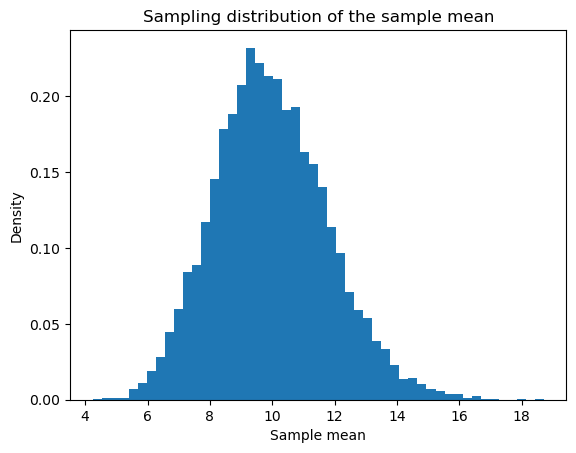

In [11]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

# A positively skewed population
population = rng.exponential(scale=10, size=200_000)

# Repeated samples; each row represents one sample
n = 30
num_samples = 10_000

samples = rng.exponential(
    scale=10,
    size=(num_samples, n)
)

sample_means = samples.mean(axis=1)

fig, ax = plt.subplots()
ax.hist(sample_means, bins=50, density=True)
ax.set_title("Sampling distribution of the sample mean")
ax.set_xlabel("Sample mean")
ax.set_ylabel("Density")
plt.show()

In [12]:
import numpy as np
from scipy.stats import norm

# Observed data summary
mu_0 = 60.0
sample_mean = 64.0
sigma = 14.142
n = 25
alpha = 0.05

# Standard error and Z-statistic
se = sigma / np.sqrt(n)
z_stat = (sample_mean - mu_0) / se

# Two-sided p-value
p_value = 2 * norm.sf(abs(z_stat))

# 95% confidence interval
critical_z = norm.ppf(1 - alpha / 2)
margin_of_error = critical_z * se
ci_lower = sample_mean - margin_of_error
ci_upper = sample_mean + margin_of_error

print(f"Standard error: {se:.4f}")
print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.4f}")
print(f"95% CI: [{ci_lower:.2f}, {ci_upper:.2f}]")

if p_value <= alpha:
    print("Reject the null hypothesis.")
else:
    print("Fail to reject the null hypothesis.")

Standard error: 2.8284
Z-statistic: 1.4142
P-value: 0.1573
95% CI: [58.46, 69.54]
Fail to reject the null hypothesis.


# 5 Point Summary Understanding 

In [13]:
import numpy as np
import matplotlib.pyplot as plt


# 1. Generate reproducible random data
rng = np.random.default_rng(42)

data = np.concatenate([
    rng.normal(loc=50, scale=8, size=50),
    [10, 105, 115]  # Injected extreme values for demonstration
])
data

array([ 52.43773664,  41.68012715,  56.00360957,  57.52451773,
        34.39171849,  39.58256395,  51.02272323,  47.47005926,
        49.86559074,  43.17564858,  57.0351838 ,  56.22233548,
        50.52824558,  59.01792966,  53.74007474,  43.1256603 ,
        52.95000627,  42.32893919,  57.02760241,  49.60059271,
        48.52110109,  44.55256364,  59.78033071,  48.76376414,
        46.57337742,  47.1829316 ,  54.25847348,  52.92355251,
        53.30186089,  53.44656802,  67.13318081,  46.74867987,
        45.90205817,  43.48981817,  54.92783538,  59.03177834,
        49.08842034,  43.27874818,  43.40415027,  55.2047423 ,
        55.94603337,  54.34523415,  44.67592234,  51.85729058,
        50.93348647,  51.74950877,  56.97143022,  51.78876439,
        55.4313085 ,  50.54063256,  10.        , 105.        ,
       115.        ])

FIVE-NUMBER SUMMARY
Minimum   : 10.000
Q1        : 46.573
Median    : 51.750
Q3        : 55.431
Maximum   : 115.000

IQR FENCES
Lower: 33.286
Upper: 68.718

POTENTIAL OUTLIERS
[ 10. 105. 115.]

ALL Z-SCORES
[ 0.017 -0.748  0.271  0.379 -1.267 -0.897 -0.084 -0.336 -0.166 -0.642
  0.344  0.286 -0.119  0.485  0.11  -0.645  0.054 -0.702  0.344 -0.185
 -0.262 -0.544  0.539 -0.244 -0.4   -0.357  0.147  0.052  0.079  0.089
  1.063 -0.388 -0.448 -0.62   0.194  0.486 -0.221 -0.635 -0.626  0.214
  0.267  0.153 -0.535 -0.024 -0.09  -0.032  0.34  -0.029  0.23  -0.118
 -3.002  3.756  4.468]


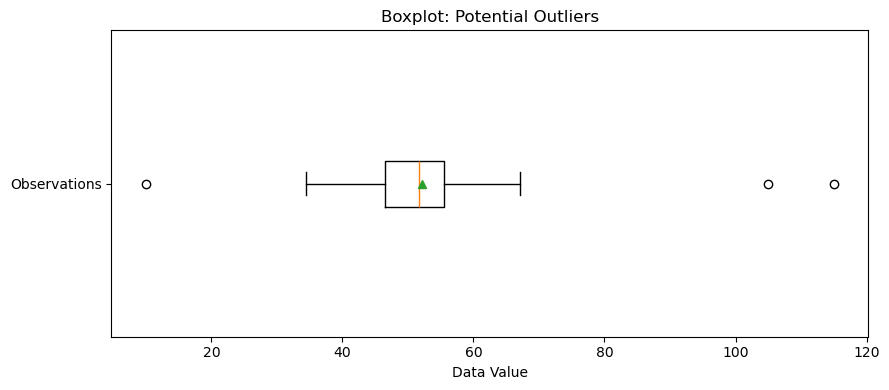

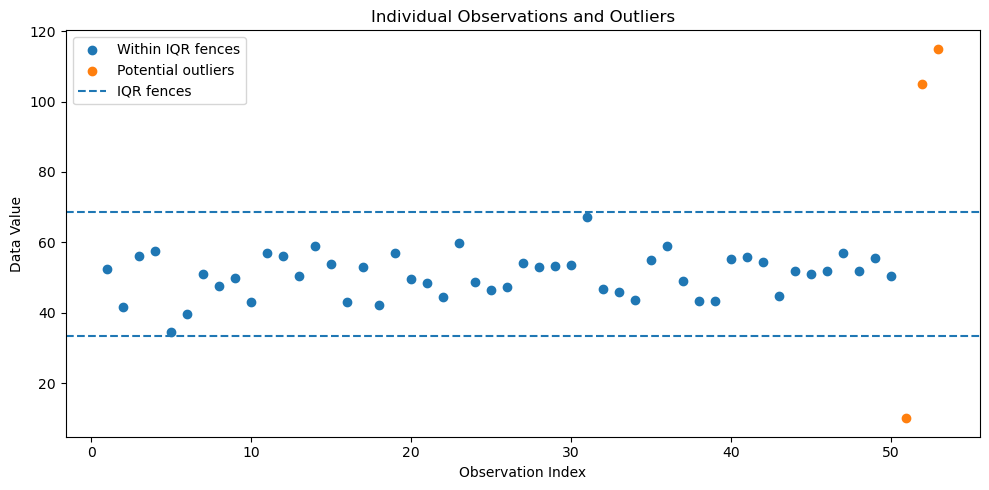

In [14]:
# 2. Calculate Z-scores
def calculate_z_scores(values, ddof=0):
    """
    Calculate z-scores:
        z = (x - mean) / standard_deviation

    ddof=0: population standard deviation => refers to degree of freedom
    ddof=1: sample standard deviation
    """
    x = np.asarray(values, dtype=float)

    if x.ndim != 1 or x.size < 2:
        raise ValueError("Provide at least two one-dimensional values.")

    if not np.all(np.isfinite(x)):
        raise ValueError("Values must be finite.")

    std = np.std(x, ddof=ddof)

    if std == 0:
        raise ValueError("Z-scores are undefined when SD is zero.")

    return (x - np.mean(x)) / std


# 3. Calculate the five-number summary
def five_point_summary(values):
    """
    Returns:
        Minimum, Q1, Median, Q3, Maximum
    """
    x = np.asarray(values, dtype=float)

    if x.ndim != 1 or x.size == 0:
        raise ValueError("Provide a non-empty one-dimensional dataset.")

    if not np.all(np.isfinite(x)):
        raise ValueError("Values must be finite.")

    names = ["Minimum", "Q1", "Median", "Q3", "Maximum"]
    numbers = np.percentile(x, [0, 25, 50, 75, 100])

    return dict(zip(names, numbers.tolist()))


# 4. Detect potential outliers using the IQR rule
def detect_iqr_outliers(values, multiplier=1.5):
    """
    Returns the lower fence, upper fence, and outlier mask.
    """
    x = np.asarray(values, dtype=float)

    if x.ndim != 1 or x.size == 0:
        raise ValueError("Provide a non-empty one-dimensional dataset.")

    if not np.all(np.isfinite(x)):
        raise ValueError("Values must be finite.")

    if multiplier < 0:
        raise ValueError("Multiplier must be non-negative.")

    q1, q3 = np.percentile(x, [25, 75])
    iqr = q3 - q1

    lower_fence = q1 - multiplier * iqr
    upper_fence = q3 + multiplier * iqr

    outlier_mask = (
        (x < lower_fence) | (x > upper_fence)
    )

    return lower_fence, upper_fence, outlier_mask


# 5. Run the functions
z_scores = calculate_z_scores(data)
summary = five_point_summary(data)

lower, upper, outliers = detect_iqr_outliers(data)

print("FIVE-NUMBER SUMMARY")
for name, value in summary.items():
    print(f"{name:10s}: {value:.3f}")

print("\nIQR FENCES")
print("Lower:", round(lower, 3))
print("Upper:", round(upper, 3))

print("\nPOTENTIAL OUTLIERS")
print(data[outliers])

print("\nALL Z-SCORES")
print(np.round(z_scores, 3))


# 6. Visualize using a boxplot
plt.figure(figsize=(9, 4))

plt.boxplot(data, vert=False, showmeans=True)

plt.title("Boxplot: Potential Outliers")
plt.xlabel("Data Value")
plt.yticks([1], ["Observations"])

plt.tight_layout()
plt.show()


# 7. Visualize individual observations
indices = np.arange(1, len(data) + 1)

plt.figure(figsize=(10, 5))

plt.scatter(
    indices[~outliers],
    data[~outliers],
    label="Within IQR fences"
)

plt.scatter(
    indices[outliers],
    data[outliers],
    label="Potential outliers"
)

plt.axhline(lower, linestyle="--", label="IQR fences")
plt.axhline(upper, linestyle="--")

plt.title("Individual Observations and Outliers")
plt.xlabel("Observation Index")
plt.ylabel("Data Value")
plt.legend()

plt.tight_layout()
plt.show()

## 1. Import libraries and load the dataset

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
path = "Mall_Customers.csv"
df = pd.read_csv(path)

# Display basic information
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

Dataset shape: (200, 5)

First five rows:


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Missing values:


CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

### 2. Select numerical features
We exclude CustomerID because it is an identifier, not a meaningful measurement of customer behaviour.

In [18]:
numeric_cols = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

X = df[numeric_cols]

print("Numerical features:")
display(X.head())

Numerical features:


,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


### 3. Calculate descriptive statistics
This gives you the mean, median, variance, standard deviation, minimum, maximum, and quartiles for each feature.

In [19]:
def descriptive_statistics(data):
    results = pd.DataFrame(index=data.columns)

    results["Count"] = data.count()
    results["Mean"] = data.mean()
    results["Median"] = data.median()
    results["Population Variance"] = data.var(ddof=0)
    results["Sample Variance"] = data.var(ddof=1)
    results["Population SD"] = data.std(ddof=0)
    results["Sample SD"] = data.std(ddof=1)
    results["Minimum"] = data.min()
    results["Q1"] = data.quantile(0.25)
    results["Q3"] = data.quantile(0.75)
    results["Maximum"] = data.max()

    return results.round(3)


stats = descriptive_statistics(X)
display(stats)

,Count,Mean,Median,Population Variance,Sample Variance,Population SD,Sample SD,Minimum,Q1,Q3,Maximum
Age,200,38.85,36.0,194.158,195.133,13.934,13.969,18,28.75,49.0,70
Annual Income (k$),200,60.56,61.5,686.386,689.836,26.199,26.265,15,41.50,78.0,137
Spending Score (1-100),200,50.20,50.0,663.520,666.854,25.759,25.824,1,34.75,73.0,99


Interview connection: Population variance divides by $(n)$, whereas sample variance divides by $(n-1)$. Pandas uses $ddof=1$ by default for $.var()$ and $.std()$, so we explicitly set ddof to distinguish the two

## 4. Calculate Z-scores using a reusable function
The Z-score tells you how many standard deviations a value lies above or below its feature's mean.
 $[
z=\frac{x-\mu}{\sigma}
]$

Here, we'll use the population standard deviation (ddof=0) for standardization

In [21]:
def calculate_z_scores(data, ddof=0):
    """
    Calculate feature-wise Z-scores.

    ddof=0: population standard deviation
    ddof=1: sample standard deviation
    """
    data = data.astype(float)

    if data.isnull().any().any():
        raise ValueError("Handle missing values before calculating Z-scores.")

    std = data.std(ddof=ddof)

    if (std == 0).any():
        raise ValueError("Cannot calculate Z-scores for constant columns.")

    return (data - data.mean()) / std


z_scores = calculate_z_scores(X)

print("Z-scores for the first five customers:")
display(z_scores.head().round(3))

Z-scores for the first five customers:


,Age,Annual Income (k$),Spending Score (1-100)
0,-1.425,-1.739,-0.435
1,-1.281,-1.739,1.196
2,-1.353,-1.701,-1.716
3,-1.138,-1.701,1.040
4,-0.563,-1.663,-0.396


In [23]:
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Flag potential outliers using $(|z|>3)$

In [24]:
z_threshold = 3

z_outlier_mask = z_scores.abs() > z_threshold

print("Number of flagged observations per feature:")
display(z_outlier_mask.sum().rename("Outlier Count").to_frame())

print("Customers flagged by Z-score:")
display(
    df.loc[z_outlier_mask.any(axis=1), ["CustomerID"] + numeric_cols]
       .assign(
           **{
               f"Z_{col}": z_scores[col]
               for col in numeric_cols
           }
       )
       .round(3)
)

Number of flagged observations per feature:


,Outlier Count
Age,0
Annual Income (k$),0
Spending Score (1-100),0


Customers flagged by Z-score:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Z_Age,Z_Annual Income (k$),Z_Spending Score (1-100)
0,NaN,NaN,NaN,NaN,-1.425,-1.739,-0.435
1,NaN,NaN,NaN,NaN,-1.281,-1.739,1.196
2,NaN,NaN,NaN,NaN,-1.353,-1.701,-1.716
3,NaN,NaN,NaN,NaN,-1.138,-1.701,1.040
4,NaN,NaN,NaN,NaN,-0.563,-1.663,-0.396
...,...,...,...,...,...,...,...
195,NaN,NaN,NaN,NaN,-0.276,2.269,1.118
196,NaN,NaN,NaN,NaN,0.441,2.498,-0.862
197,NaN,NaN,NaN,NaN,-0.492,2.498,0.924
198,NaN,NaN,NaN,NaN,-0.492,2.918,-1.250


The Z-score rule is a heuristic, not a universal definition of an outlier. It can be less reliable for skewed distributions because extreme values affect the mean and standard deviation.

## 5. Calculate the five-number summary
The five-number summary consists of:
1. Minimum
2. First quartile $((Q_1))$
3. Median $((Q_2))$
4. Third quartile $((Q_3))$
5. Maximum

In [25]:
def five_number_summary(data):
    summary = pd.DataFrame(index=data.columns)

    summary["Minimum"] = data.min()
    summary["Q1"] = data.quantile(0.25)
    summary["Median"] = data.quantile(0.50)
    summary["Q3"] = data.quantile(0.75)
    summary["Maximum"] = data.max()

    return summary.round(3)


five_summary = five_number_summary(X)
display(five_summary)

,Minimum,Q1,Median,Q3,Maximum
Age,18,28.75,36.0,49.0,70
Annual Income (k$),15,41.50,61.5,78.0,137
Spending Score (1-100),1,34.75,50.0,73.0,99


Mathematical connection
The interquartile range (IQR) is the spread of the middle 50% of observations:
$[
IQR=Q_3-Q_1
] $

The IQR is particularly useful because it is less affected by extreme observations than the range or standard deviation.

## 6. Detect outliers using the IQR method
The conventional IQR fences are: \
$
L=Q_1-1.5(IQR)
 $

 $ 
U=Q_3+1.5(IQR)
 $

An observation is flagged when $(x<L) or  $(x>U)$

In [26]:
def detect_iqr_outliers(data, multiplier=1.5):
    results = pd.DataFrame(index=data.columns)

    results["Q1"] = data.quantile(0.25)
    results["Q3"] = data.quantile(0.75)
    results["IQR"] = results["Q3"] - results["Q1"]

    results["Lower Fence"] = (
        results["Q1"] - multiplier * results["IQR"]
    )
    results["Upper Fence"] = (
        results["Q3"] + multiplier * results["IQR"]
    )

    mask = pd.DataFrame(
        False, index=data.index, columns=data.columns
    )

    for col in data.columns:
        mask[col] = (
            (data[col] < results.loc[col, "Lower Fence"]) |
            (data[col] > results.loc[col, "Upper Fence"])
        )

    return results.round(3), mask


iqr_summary, iqr_outlier_mask = detect_iqr_outliers(X)

print("IQR boundaries:")
display(iqr_summary)

print("Number of IQR outliers per feature:")
display(iqr_outlier_mask.sum().rename("Outlier Count").to_frame())

IQR boundaries:


,Q1,Q3,IQR,Lower Fence,Upper Fence
Age,28.75,49.0,20.25,-1.625,79.375
Annual Income (k$),41.50,78.0,36.50,-13.250,132.750
Spending Score (1-100),34.75,73.0,38.25,-22.625,130.375


Number of IQR outliers per feature:


,Outlier Count
Age,0
Annual Income (k$),2
Spending Score (1-100),0


Display the actual customers flagged

In [27]:
iqr_outliers = df.loc[
    iqr_outlier_mask.any(axis=1),
    ["CustomerID"] + numeric_cols
].copy()

iqr_outliers["Flagged Features"] = [
    ", ".join(iqr_outlier_mask.columns[row].tolist())
    for row in iqr_outlier_mask.loc[iqr_outliers.index].to_numpy()
]

display(iqr_outliers)

,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Flagged Features
198,199,32,137,18,Annual Income (k$)
199,200,30,137,83,Annual Income (k$)


A customer can be flagged in more than one feature. These are candidates for investigation, not necessarily incorrect records.

## 7. Visualize distributions and outliers
#### A. Boxplots 
The box shows the interquartile range, the line inside the box marks the median, and points beyond the whiskers indicate potential outliers under the plotting convention.

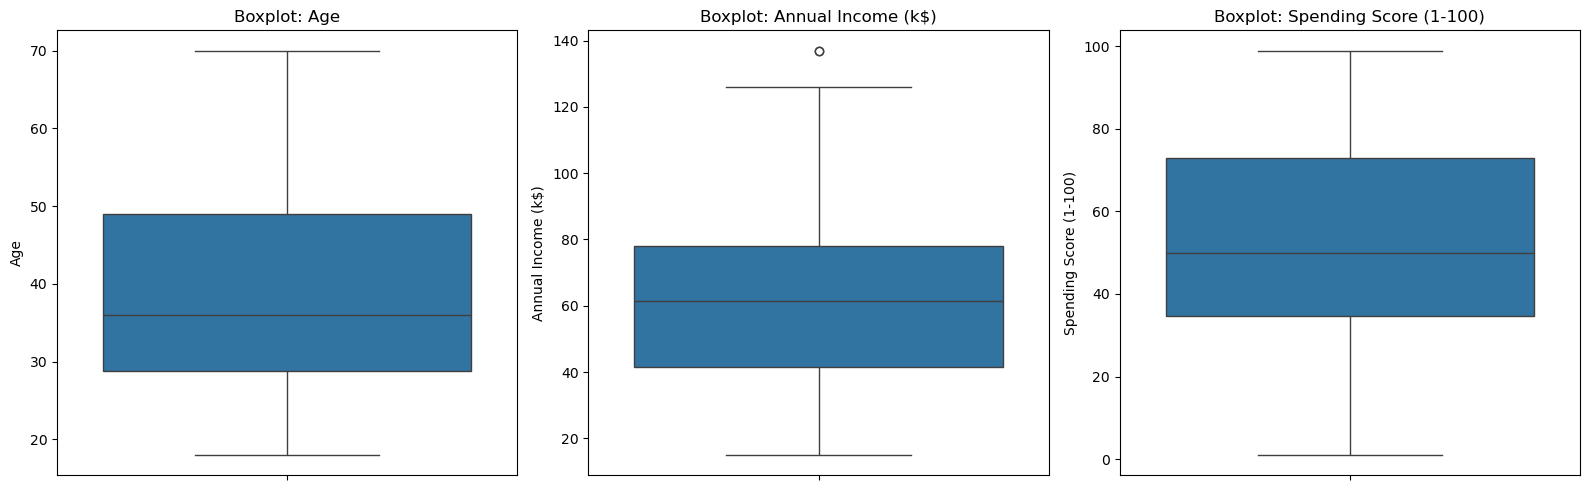

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(f"Boxplot: {col}")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

### B. Histograms
Histograms help you understand the distribution's shape, skewness, and concentration.

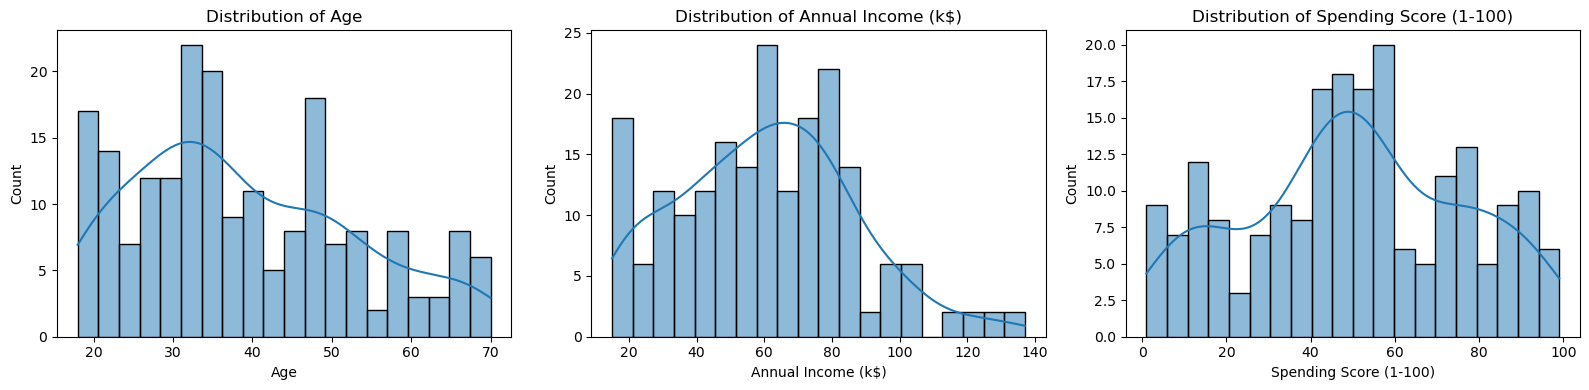

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, col in zip(axes, numeric_cols):
    sns.histplot(df[col], kde=True, ax=ax, bins=20)
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

### C. Scatter plots with IQR outliers highlighted
Each observation is coloured according to whether it was flagged for the selected feature.

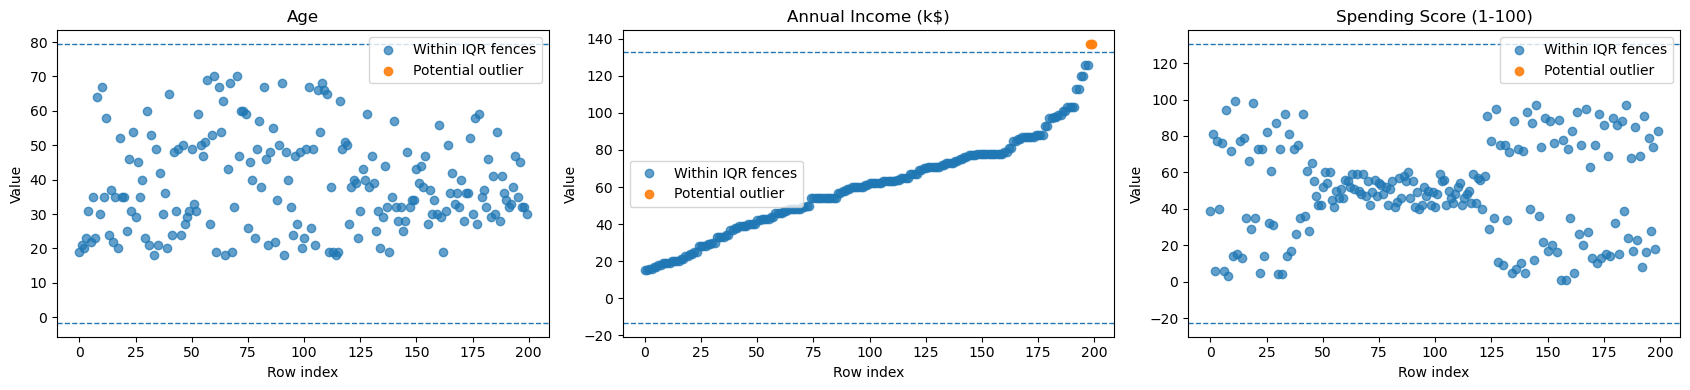

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

for ax, col in zip(axes, numeric_cols):
    mask = iqr_outlier_mask[col]

    ax.scatter(
        df.index[~mask], df.loc[~mask, col],
        label="Within IQR fences", alpha=0.7
    )

    ax.scatter(
        df.index[mask], df.loc[mask, col],
        label="Potential outlier", alpha=0.9
    )

    ax.axhline(
        iqr_summary.loc[col, "Lower Fence"],
        linestyle="--", linewidth=1
    )
    ax.axhline(
        iqr_summary.loc[col, "Upper Fence"],
        linestyle="--", linewidth=1
    )

    ax.set_title(col)
    ax.set_xlabel("Row index")
    ax.set_ylabel("Value")
    ax.legend()

plt.tight_layout()
plt.show()

### 8. Compare Z-score and IQR detection
This is an important data science exercise because the two methods use different definitions of unusual observations.

In [31]:
comparison = pd.DataFrame(index=numeric_cols)

comparison["Z-score Flags (|z| > 3)"] = z_outlier_mask.sum()
comparison["IQR Flags"] = iqr_outlier_mask.sum()

display(comparison)

# Customers flagged by either method
any_outlier = (
    z_outlier_mask.any(axis=1) |
    iqr_outlier_mask.any(axis=1)
)

outlier_comparison = df.loc[
    any_outlier, ["CustomerID"] + numeric_cols
].copy()

for col in numeric_cols:
    outlier_comparison[f"Z_{col}"] = z_scores.loc[
        outlier_comparison.index, col
    ]
    outlier_comparison[f"IQR_{col}"] = iqr_outlier_mask.loc[
        outlier_comparison.index, col
    ]

display(outlier_comparison.round(3))

,Z-score Flags (|z| > 3),IQR Flags
Age,0,0
Annual Income (k$),0,2
Spending Score (1-100),0,0


,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Z_Age,IQR_Age,Z_Annual Income (k$),IQR_Annual Income (k$),Z_Spending Score (1-100),IQR_Spending Score (1-100)
198,199,32,137,18,-0.492,False,2.918,True,-1.250,False
199,200,30,137,83,-0.635,False,2.918,True,1.273,False


### How to interpret the comparison:
- If both methods flag a customer, the observation deserves investigation.
- If only IQR flags it, the feature's distribution or the mean and standard deviation may explain the difference.
- If neither method flags an observation, it can still be unusual in combination with other features.

### 9. Investigate multivariate relationships
Your dataset is especially useful for clustering exercises because it contains age, income, and spending score.

For example, a customer with ordinary income and spending individually might still have an unusual combination of the two.

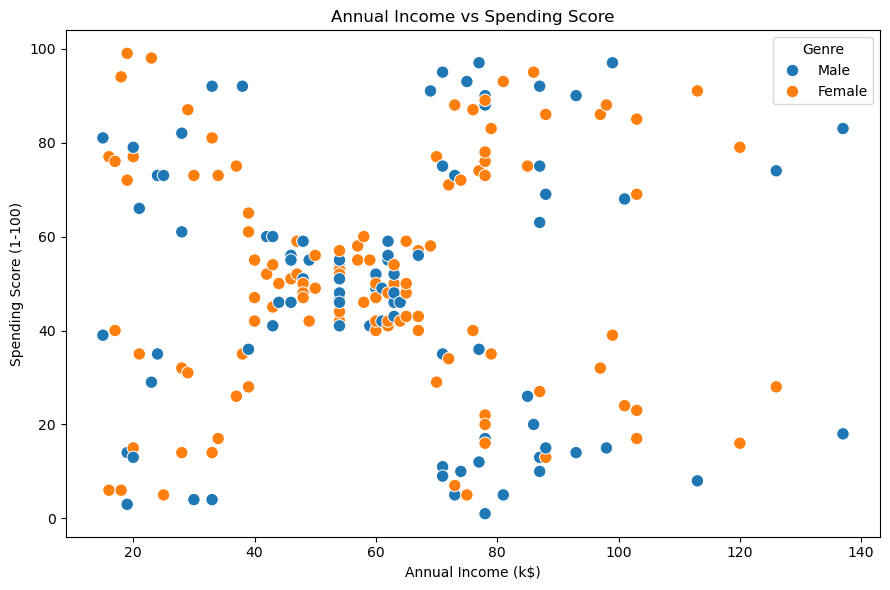

In [32]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Genre",
    s=80
)

plt.title("Annual Income vs Spending Score")
plt.tight_layout()
plt.show()